# Hotel Booking Data Analysis

**Course:** Data Processing with Python (HAMK)

**Group members:**
1. Anup Kandel
2. Sandesh Bishokarma
3. Sushant Koirala
4. Tanka Raj Aryal

## Context and research questions

**What one row represents:** 

one hotel booking (completed or cancelled), with details of the stay (dates, nights, guests), how it was booked (market segment, deposit type, customer type) and its price (average daily rate in euros).

**Population and time period:** 

bookings at a city hotel (Lisbon) and a resort hotel (Algarve), Portugal, with arrival dates from July 2015 to August 2017. This is a 1,000-record sample of the Hotel Booking Demand dataset (António, de Almeida & Nunes, 2019).

**Purpose of the analysis:** 

the audience is hotel management. We want to help them understand **which bookings are more likely to be cancelled** and **how demand differs between the two hotels**, so they can plan capacity, deposits and pricing.

**Research questions**

1. *(categorical comparison)* Do cancellation rates differ between the City Hotel and the Resort Hotel?
2. *(numerical variable)* Is lead time (days between booking and arrival) associated with cancellation?
3. *(time pattern)* How does booking volume vary by arrival month for each hotel?

**Responsible:** Tanka Raj Aryal. The three research questions are agreed by the whole group at the kickoff (led by Sandesh Bishokarma).

## Imports and display settings

**Responsible:** Tanka Raj Aryal.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:.2f}".format)
plt.rcParams.update({
    "figure.figsize": (9, 5),
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "axes.grid": True,
    "grid.alpha": 0.25,
})

DATA_FILE = "../data/hotel_bookings_final_project.csv"

## Load and inspect the data

Use Pandas to load the CSV and inspect the dataset: number of rows and columns; column names and data types;
a small preview or random sample; missing values; exact duplicates; useful category counts; numerical summary statistics.
Do not print large amounts of unnecessary output.

**Responsible:** Tanka Raj Aryal.

In [2]:
hotel_raw = pd.read_csv(DATA_FILE)
print(f"Rows: {hotel_raw.shape[0]}, columns: {hotel_raw.shape[1]}")
hotel_raw.head()

Rows: 1000, columns: 20


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,country,market_segment,deposit_type,customer_type,average_daily_rate,is_repeated_guest,booking_changes,required_car_parking_spaces,total_of_special_requests
0,City Hotel,1,1,2015,September,30,0,2,1,0,0,PRT,Offline TA/TO,Non Refund,Transient,98.10,1,0,0,0
1,Resort Hotel,1,19,2016,March,19,2,4,2,0,0,PRT,Online TA,No Deposit,Transient,70.17,0,0,0,1
2,Resort Hotel,0,9,2017,August,1,0,4,2,0,0,ESP,Online TA,No Deposit,Transient,193.40,0,0,0,1
3,Resort Hotel,0,110,2016,November,11,0,1,2,0,0,BRA,Online TA,No Deposit,Transient,36.24,0,2,1,0
4,City Hotel,0,329,2017,July,27,0,2,2,0,0,GBR,Online TA,No Deposit,Transient,89.10,0,0,0,1


In [3]:
print("Rows and columns:", hotel_raw.shape)
print("Columns:", hotel_raw.columns.tolist())
hotel_raw.info()

Rows and columns: (1000, 20)
Columns: ['hotel', 'is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'country', 'market_segment', 'deposit_type', 'customer_type', 'average_daily_rate', 'is_repeated_guest', 'booking_changes', 'required_car_parking_spaces', 'total_of_special_requests']
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   hotel                        1000 non-null   str    
 1   is_canceled                  1000 non-null   int64  
 2   lead_time                    1000 non-null   int64  
 3   arrival_date_year            1000 non-null   int64  
 4   arrival_date_month           1000 non-null   str    
 5   arrival_date_day_of_month    1000 non-null   int64  
 6   stays_in_weekend_nigh

In [4]:
# Count missing values and duplicate rows
missing = hotel_raw.isna().sum()
print("Missing values per column (only columns with any):")
print(missing[missing > 0])
print("\nExact duplicate rows:", hotel_raw.duplicated().sum())

# Display the category labels in sorted order
print("\nHotel labels:", sorted(hotel_raw["hotel"].dropna().unique()))
print("Deposit labels:", sorted(hotel_raw["deposit_type"].dropna().unique()))
print("Month labels:", hotel_raw["arrival_date_month"].nunique(), "different months")

Missing values per column (only columns with any):
country    2
dtype: int64

Exact duplicate rows: 26

Hotel labels: ['City Hotel', 'Resort Hotel']
Deposit labels: ['No Deposit', 'Non Refund', 'Refundable']
Month labels: 12 different months


In [5]:
# Count the values in the main category columns
for col in ["hotel", "is_canceled", "market_segment", "deposit_type", "customer_type"]:
    print(f"--- {col} ---")
    print(hotel_raw[col].value_counts(dropna=False), "\n")

--- hotel ---
hotel
City Hotel      642
Resort Hotel    358
Name: count, dtype: int64 

--- is_canceled ---
is_canceled
0    634
1    366
Name: count, dtype: int64 

--- market_segment ---
market_segment
Online TA        481
Offline TA/TO    209
Groups           163
Direct           100
Corporate         41
Complementary      6
Name: count, dtype: int64 

--- deposit_type ---
deposit_type
No Deposit    881
Non Refund    116
Refundable      3
Name: count, dtype: int64 

--- customer_type ---
customer_type
Transient          742
Transient-Party    226
Contract            28
Group                4
Name: count, dtype: int64 


In [6]:
# Show summary statistics for all numeric columns, rounded to 2 decimal places
hotel_raw.select_dtypes(include="number").describe().round(2)

,is_canceled,lead_time,arrival_date_year,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,average_daily_rate,is_repeated_guest,booking_changes,required_car_parking_spaces,total_of_special_requests
count,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00
mean,0.37,105.06,2016.13,16.13,0.92,2.52,1.86,0.11,0.01,101.21,0.03,0.24,0.06,0.59
std,0.48,106.45,0.70,8.96,0.95,1.80,0.53,0.40,0.09,45.72,0.18,0.67,0.24,0.80
min,0.00,0.00,2015.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,0.00,19.00,2016.00,8.00,0.00,1.00,2.00,0.00,0.00,68.57,0.00,0.00,0.00,0.00
50%,0.00,69.50,2016.00,16.00,1.00,2.00,2.00,0.00,0.00,94.50,0.00,0.00,0.00,0.00
75%,1.00,157.00,2017.00,24.00,2.00,3.00,2.00,0.00,0.00,125.00,0.00,0.00,0.00,1.00
max,1.00,542.00,2017.00,31.00,8.00,20.00,6.00,3.00,1.00,304.00,1.00,7.00,1.00,5.00


In [7]:
# Show which months each year covers
year_coverage = (
    hotel_raw.groupby("arrival_date_year")
    .agg(
        months_covered=("arrival_date_month", "nunique"),
        bookings=("hotel", "count"),
    )
)
year_coverage

,months_covered,bookings
arrival_date_year,,
2015,6,188
2016,12,490
2017,8,322


**What the inspection shows:** the file has 1,000 rows and 20 columns. Only `country` has missing values (2 rows), and there are 26 exact duplicate rows. 64.2 % of bookings are at the City Hotel and 36.6 % of all bookings were cancelled.
The years are **not complete calendar years**: 2015 covers only July–December (6 months) and 2017 only January–August (8 months). We must keep this in mind when we compare months.

## Data-quality assessment and cleaning log

At minimum, investigate: missing values; exact duplicates; invalid date combinations; impossible negative values;
bookings with zero total guests; bookings with zero total nights; unusual values in `lead_time`; unusual values in `average_daily_rate`.


Keep the original DataFrame unchanged and create a cleaned copy.

**Responsible:** Tanka Raj Aryal.

In [8]:
# Create helper columns for the data-quality checks
check = hotel_raw.copy()
check["nights_tmp"] = check["stays_in_weekend_nights"] + check["stays_in_week_nights"]
check["guests_tmp"] = check["adults"] + check["children"] + check["babies"]
check["date_tmp"] = pd.to_datetime(
    check["arrival_date_year"].astype(str) + "-" + check["arrival_date_month"] + "-"
    + check["arrival_date_day_of_month"].astype(str),
    format="%Y-%B-%d", errors="coerce")

def iqr_upper_fence(series):
    q1, q3 = series.quantile([0.25, 0.75])
    return q3 + 1.5 * (q3 - q1)

# Count the rows affected by each issue
numeric_cols = hotel_raw.select_dtypes("number").columns
checks = {
    "missing values (any column)": hotel_raw.isna().any(axis=1).sum(),
    "exact duplicate rows": hotel_raw.duplicated().sum(),
    "invalid date combinations": check["date_tmp"].isna().sum(),
    "rows with a negative numeric value": (hotel_raw[numeric_cols] < 0).any(axis=1).sum(),
    "zero total guests": (check["guests_tmp"] == 0).sum(),
    "zero total nights": (check["nights_tmp"] == 0).sum(),
    "lead_time above IQR fence": (hotel_raw["lead_time"] > iqr_upper_fence(hotel_raw["lead_time"])).sum(),
    "average_daily_rate above IQR fence": (hotel_raw["average_daily_rate"] > iqr_upper_fence(hotel_raw["average_daily_rate"])).sum(),
    "average_daily_rate == 0": (hotel_raw["average_daily_rate"] == 0).sum(),
}
print("lead_time fence:", round(iqr_upper_fence(hotel_raw["lead_time"]), 1), "days")
print("average_daily_rate fence:", round(iqr_upper_fence(hotel_raw["average_daily_rate"]), 1), "EUR")
pd.Series(checks, name="affected rows").to_frame()

lead_time fence: 364.0 days
average_daily_rate fence: 209.6 EUR


,affected rows
missing values (any column),2
exact duplicate rows,26
invalid date combinations,0
rows with a negative numeric value,0
zero total guests,3
zero total nights,5
lead_time above IQR fence,28
average_daily_rate above IQR fence,25
average_daily_rate == 0,15


In [9]:
# Display the bookings with zero nights or zero guests
check.loc[(check["nights_tmp"] == 0) | (check["guests_tmp"] == 0),
          ["hotel", "is_canceled", "adults", "children", "babies", "nights_tmp", "average_daily_rate", "market_segment"]]

,hotel,is_canceled,adults,children,babies,nights_tmp,average_daily_rate,market_segment
201,City Hotel,0,0,0,0,0,0.00,Online TA
455,Resort Hotel,0,1,0,0,0,0.00,Groups
461,City Hotel,0,1,0,0,0,0.00,Offline TA/TO
774,City Hotel,0,0,0,0,0,0.00,Offline TA/TO
993,City Hotel,0,0,0,0,0,0.00,Online TA


In [10]:
# Display the duplicate rows
hotel_raw[hotel_raw.duplicated(keep=False)].sort_values(list(hotel_raw.columns)).head(10)

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,country,market_segment,deposit_type,customer_type,average_daily_rate,is_repeated_guest,booking_changes,required_car_parking_spaces,total_of_special_requests
353,City Hotel,0,11,2015,December,5,2,2,2,0,0,PRT,Groups,No Deposit,Transient-Party,104.00,0,0,0,0
638,City Hotel,0,11,2015,December,5,2,2,2,0,0,PRT,Groups,No Deposit,Transient-Party,104.00,0,0,0,0
276,City Hotel,0,55,2015,September,6,2,0,2,0,0,ESP,Groups,No Deposit,Transient-Party,75.00,0,0,0,0
535,City Hotel,0,55,2015,September,6,2,0,2,0,0,ESP,Groups,No Deposit,Transient-Party,75.00,0,0,0,0
116,City Hotel,0,102,2015,October,16,0,2,2,0,0,DEU,Offline TA/TO,No Deposit,Transient-Party,109.00,0,0,0,0
957,City Hotel,0,102,2015,October,16,0,2,2,0,0,DEU,Offline TA/TO,No Deposit,Transient-Party,109.00,0,0,0,0
263,City Hotel,0,134,2016,April,9,1,1,2,0,0,PRT,Groups,No Deposit,Transient-Party,90.00,0,0,0,1
713,City Hotel,0,134,2016,April,9,1,1,2,0,0,PRT,Groups,No Deposit,Transient-Party,90.00,0,0,0,1
486,City Hotel,0,377,2016,October,14,0,2,2,0,0,DEU,Offline TA/TO,No Deposit,Transient-Party,115.00,0,0,0,1
804,City Hotel,0,377,2016,October,14,0,2,2,0,0,DEU,Offline TA/TO,No Deposit,Transient-Party,115.00,0,0,0,1


In [11]:
# Show the market segment of duplicates and of free (0 EUR) bookings
print("Market segment of duplicated rows:")
print(hotel_raw.loc[hotel_raw.duplicated(keep=False), "market_segment"].value_counts())

print("\nMarket segment of bookings with average_daily_rate == 0:")
print(hotel_raw.loc[hotel_raw["average_daily_rate"] == 0, "market_segment"].value_counts())

Market segment of duplicated rows:
market_segment
Groups           32
Offline TA/TO    19
Name: count, dtype: int64

Market segment of bookings with average_daily_rate == 0:
market_segment
Complementary    6
Online TA        3
Offline TA/TO    3
Groups           2
Direct           1
Name: count, dtype: int64


In [12]:
# Show the largest lead times and daily rates
print("Largest lead times (days):", hotel_raw["lead_time"].nlargest(5).tolist())
print("Largest daily rates (EUR):", hotel_raw["average_daily_rate"].nlargest(5).tolist())

# Find daily rates outside the valid range of 0 to 500 EUR
invalid_rates = hotel_raw.loc[
    hotel_raw["average_daily_rate"].notna() &
    ~hotel_raw["average_daily_rate"].between(0, 500)
]
print("Daily rates outside 0-500 EUR:", len(invalid_rates))

Largest lead times (days): [542, 538, 531, 517, 496]
Largest daily rates (EUR): [304.0, 284.2, 283.6, 275.0, 271.0]
Daily rates outside 0-500 EUR: 0


### Cleaning log

| Issue checked | Evidence | Decision | Reason |
|---|---|---|---|
| Missing `country` | 2 rows (both Resort Hotel) | **Fill** with `"Unknown"` | Country is not used in our research questions; keeping the rows keeps their other information. |
| Exact duplicates | 26 rows; all are *Groups* or *Offline TA/TO* bookings | **Keep** | The dataset has no booking ID, and group / tour-operator bookings are often entered as several identical bookings, so these are most likely separate real bookings. |
| Invalid date combinations | 0 rows | No action | Every year–month–day combination converts to a real date. |
| Negative values | 0 rows | No action | No numeric column contains negative values. |
| Zero total guests | 3 rows; all also have 0 nights and a rate of 0 € | **Remove** | A booking with no guests and no nights is not a real stay; these look like placeholder records. |
| Zero total nights | 5 rows (3 are the zero-guest rows above) | **Remove 3, keep 2** | The 2 remaining rows have guests and could be day-use bookings; they stay in the data but have a booking value of 0. |
| Unusual `lead_time` | 28 rows above the 364-day fence; maximum 542 days | **Keep** | Booking 1–1.5 years ahead is rare but possible, and long lead times are central to RQ2. |
| Unusual `average_daily_rate` (incl. 0) | 25 rows above the ~210 € fence (max 304 €); 15 rows at 0 € (6 *Complementary*); none outside 0–500 € | **Keep** | High rates fit peak-season pricing and free stays are real (complimentary/promotional); 3 of the 0 € rows are removed by the zero-guest rule. |

In [13]:
# Create a copy so the original DataFrame remains unchanged
hotel = hotel_raw.copy()
rows_before = len(hotel)

# Replace missing country values with "Unknown"
hotel["country"] = hotel["country"].fillna("Unknown")

# Remove bookings with zero guests
hotel = hotel[(hotel["adults"] + hotel["children"] + hotel["babies"]) > 0].copy()

print("Rows before:", rows_before)
print("Rows after:", len(hotel))
print("Rows removed:", rows_before - len(hotel))
print("Missing values left:", hotel.isna().sum().sum())
print("hotel_raw is unchanged:", hotel_raw.shape)

Rows before: 1000
Rows after: 997
Rows removed: 3
Missing values left: 0
hotel_raw is unchanged: (1000, 20)


## Transformations and derived variables

Create at least these four derived variables:
- `arrival_date` — proper Pandas date;
- `total_nights` — weekend nights + weekday nights;
- `total_guests` — adults + children + babies;
- `estimated_booking_value` — average daily rate × total nights.

You may create additional useful variables if they support your research questions.

**Responsible:** Sushant Koirala.

In [14]:
# Create the four derived variables
hotel["arrival_date"] = pd.to_datetime(
    hotel["arrival_date_year"].astype(str) + "-" + hotel["arrival_date_month"] + "-"
    + hotel["arrival_date_day_of_month"].astype(str),
    format="%Y-%B-%d", errors="coerce")
hotel["total_nights"] = hotel["stays_in_weekend_nights"] + hotel["stays_in_week_nights"]
hotel["total_guests"] = hotel["adults"] + hotel["children"] + hotel["babies"]
hotel["estimated_booking_value"] = hotel["average_daily_rate"] * hotel["total_nights"]

# Add readable cancellation labels and the arrival month number
hotel["cancel_status"] = hotel["is_canceled"].map({0: "Not cancelled", 1: "Cancelled"})
hotel["arrival_month_num"] = hotel["arrival_date"].dt.month

hotel[["arrival_date", "total_nights", "total_guests", "average_daily_rate", "estimated_booking_value"]].head()

,arrival_date,total_nights,total_guests,average_daily_rate,estimated_booking_value
0,2015-09-30,2,1,98.10,196.20
1,2016-03-19,6,2,70.17,421.02
2,2017-08-01,4,2,193.40,773.60
3,2016-11-11,1,2,36.24,36.24
4,2017-07-27,2,2,89.10,178.20


In [15]:
# Flag early bookings and group lead time into bands
hotel["booked_far_ahead"] = hotel["lead_time"] > 180
hotel["lead_time_band"] = pd.cut(
    hotel["lead_time"],
    bins=[-1, 7, 30, 90, 180, 365, float("inf")],
    labels=["0-7", "8-30", "31-90", "91-180", "181-365", "366+"],
)

print("Invalid arrival dates:", hotel["arrival_date"].isna().sum())
print("Bookings made more than 180 days ahead:", hotel["booked_far_ahead"].sum())
print(hotel["lead_time_band"].value_counts(sort=False))

Invalid arrival dates: 0
Bookings made more than 180 days ahead: 212
lead_time_band
0-7        143
8-30       170
31-90      252
91-180     220
181-365    184
366+        28
Name: count, dtype: int64


- `arrival_date` combines the three date columns into one real date (`datetime64`); 0 dates failed to convert.
- `total_nights` and `total_guests` add up their parts; `estimated_booking_value` = daily rate × nights (euros, before any cancellation).
- `cancel_status` turns 0/1 into readable labels, `arrival_month_num` (1–12) lets us sort months in calendar order.
- `booked_far_ahead` is a True/False flag and `lead_time_band` groups lead time with `pd.cut`, as in the bike-rentals lesson (`rental_level`).

## Individual-variable analysis

Analyze at least two categorical variables and two numerical variables.
- Categorical: counts; percentages; valid sample size (n); a suitable chart when useful (bar chart).
- Numerical: valid n; mean; median; standard deviation; minimum and maximum; a suitable visualization such as a histogram or box plot.

**Responsible:** Sushant Koirala.

In [16]:
# Functions for categorical and numerical summaries
def categorical_summary(df, column):
    counts = df[column].value_counts()
    table = pd.DataFrame({"count": counts, "percent": (counts / counts.sum() * 100).round(1)})
    print(f"{column}: valid n = {counts.sum()}")
    return table

def numerical_summary(df, columns):
    return df[columns].agg(["count", "mean", "median", "std", "min", "max"]).T.rename(columns={"count": "valid_n"})

hotel_table = categorical_summary(hotel, "hotel")
hotel_table

hotel: valid n = 997


,count,percent
hotel,,
City Hotel,639,64.10
Resort Hotel,358,35.90


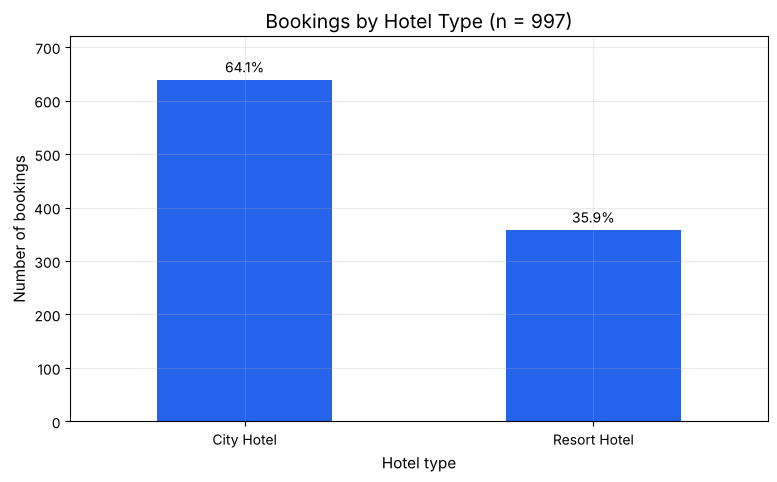

In [17]:
ax = hotel_table["count"].plot(kind="bar", color="#2563eb")
ax.bar_label(ax.containers[0], labels=[f"{p}%" for p in hotel_table["percent"]], padding=3)
ax.set_title(f"Bookings by Hotel Type (n = {hotel_table['count'].sum()})")
ax.set_xlabel("Hotel type")
ax.set_ylabel("Number of bookings")
ax.set_ylim(0, 720)
ax.tick_params(axis="x", rotation=0)
plt.show()

In [18]:
deposit_table = categorical_summary(hotel, "deposit_type")
deposit_table

deposit_type: valid n = 997


,count,percent
deposit_type,,
No Deposit,878,88.10
Non Refund,116,11.60
Refundable,3,0.30


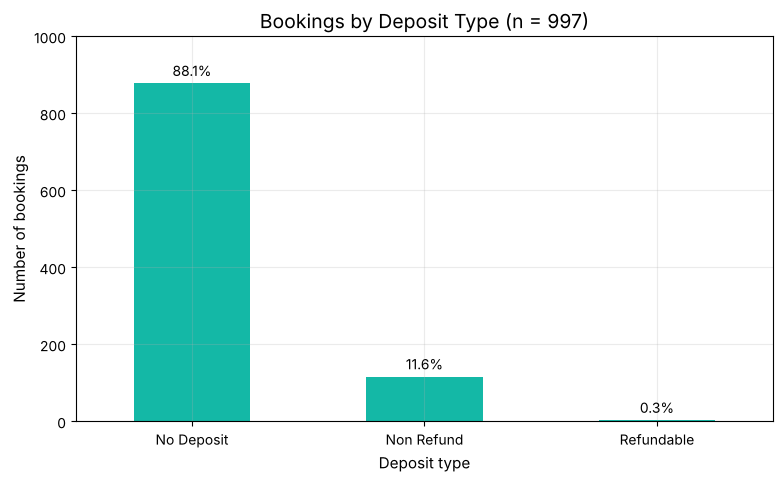

In [19]:
ax = deposit_table["count"].plot(kind="bar", color="#14b8a6")
ax.bar_label(ax.containers[0], labels=[f"{p}%" for p in deposit_table["percent"]], padding=3)
ax.set_title(f"Bookings by Deposit Type (n = {deposit_table['count'].sum()})")
ax.set_xlabel("Deposit type")
ax.set_ylabel("Number of bookings")
ax.set_ylim(0, 1000)
ax.tick_params(axis="x", rotation=0)
plt.show()

The City Hotel accounts for almost two thirds of the bookings (64.1 %). Most bookings need **no deposit** (88.1 %); *Non Refund* deposits are 11.6 % and *Refundable* deposits are very rare (0.3 %, n = 3).

In [20]:
numerical_summary(hotel, ["lead_time", "average_daily_rate", "total_nights"]).round(2)

,valid_n,mean,median,std,min,max
lead_time,997.00,105.32,71.00,106.49,0.00,542.00
average_daily_rate,997.00,101.52,94.50,45.45,0.00,304.00
total_nights,997.00,3.46,3.00,2.38,0.00,28.00


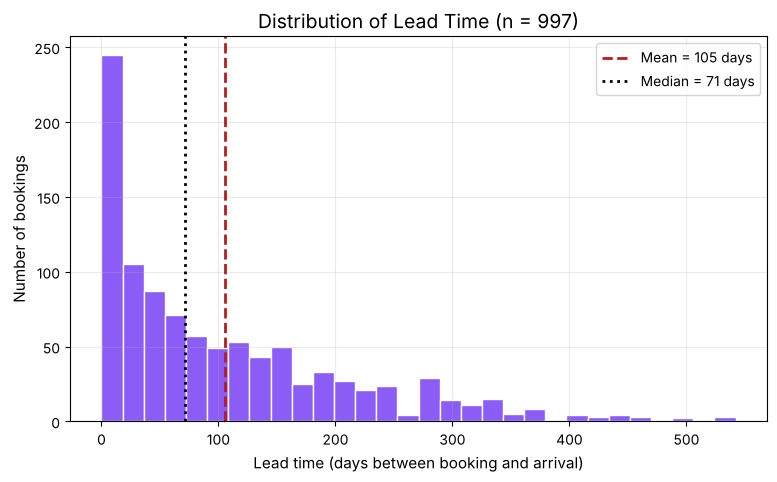

In [21]:
fig, ax = plt.subplots()
ax.hist(hotel["lead_time"], bins=30, color="#8b5cf6", edgecolor="white")
ax.axvline(np.mean(hotel["lead_time"]), color="#b91c1c", linestyle="--",
           linewidth=2, label=f"Mean = {np.mean(hotel['lead_time']):.0f} days")
ax.axvline(np.median(hotel["lead_time"]), color="black", linestyle=":",
           linewidth=2, label=f"Median = {np.median(hotel['lead_time']):.0f} days")
ax.set_title(f"Distribution of Lead Time (n = {hotel['lead_time'].notna().sum()})")
ax.set_xlabel("Lead time (days between booking and arrival)")
ax.set_ylabel("Number of bookings")
ax.legend()
plt.show()

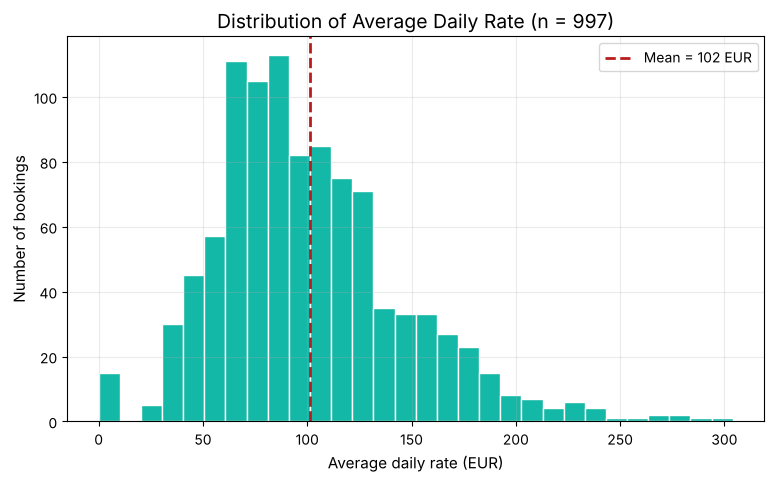

In [22]:
fig, ax = plt.subplots()
ax.hist(hotel["average_daily_rate"], bins=30, color="#14b8a6", edgecolor="white")
ax.axvline(np.mean(hotel["average_daily_rate"]), color="#b91c1c", linestyle="--",
           linewidth=2, label=f"Mean = {np.mean(hotel['average_daily_rate']):.0f} EUR")
ax.set_title(f"Distribution of Average Daily Rate (n = {hotel['average_daily_rate'].notna().sum()})")
ax.set_xlabel("Average daily rate (EUR)")
ax.set_ylabel("Number of bookings")
ax.legend()
plt.show()

**Lead time** is strongly right-skewed: most bookings are made within a few months of arrival (median 71 days), but a long tail reaches 542 days, which is why the mean (105 days) is far above the median.
**Average daily rate** is closer to symmetric around a median of about 95 €, with a small group of free (0 €) stays and a few high-season rates above 250 €.

## Relationships and grouped analysis

Complete at least three grouped or two-variable analyses. Together they must include:
- one categorical-versus-categorical analysis using a crosstab;
- one categorical-versus-numerical analysis using `groupby()` and aggregation; and
- one numerical-versus-numerical or time-based analysis.

For crosstabs, show both counts and clearly labelled percentages. State what the percentage denominator is.

**Responsible:** Sandesh Bishokarma (crosstab for RQ1, groupby for RQ2) and Anup Kandel (time-based analysis for RQ3).

### RQ1: Do cancellation rates differ between the City Hotel and the Resort Hotel?

In [23]:
# Count bookings by hotel and cancellation status
counts = pd.crosstab(hotel["hotel"], hotel["cancel_status"], margins=True, margins_name="Total")
counts

cancel_status,Cancelled,Not cancelled,Total
hotel,,,
City Hotel,279,360,639
Resort Hotel,87,271,358
Total,366,631,997


In [24]:
# Row percentages: each row adds up to 100 %
row_pct = (pd.crosstab(hotel["hotel"], hotel["cancel_status"], normalize="index") * 100).round(1)
row_pct

cancel_status,Cancelled,Not cancelled
hotel,,
City Hotel,43.70,56.30
Resort Hotel,24.30,75.70


**Denominator:** each percentage is out of all bookings for that hotel.
City Hotel bookings were cancelled in **43.7 %** of cases (279 of 639), compared with **24.3 %** (87 of 358) at the Resort Hotel.

In [25]:
# Cancellation rate by deposit type
deposit_pct = (pd.crosstab(hotel["deposit_type"], hotel["cancel_status"], normalize="index") * 100).round(1)
print("Bookings per deposit type:")
print(hotel["deposit_type"].value_counts())
deposit_pct

Bookings per deposit type:
deposit_type
No Deposit    878
Non Refund    116
Refundable      3
Name: count, dtype: int64


cancel_status,Cancelled,Not cancelled
deposit_type,,
No Deposit,28.50,71.50
Non Refund,100.00,0.00
Refundable,0.00,100.00


All 116 *Non Refund* bookings were cancelled, compared with 28.5 % of *No Deposit* bookings. This is unusual, so we report it with caution and make no causal claim.

### RQ2: Is lead time associated with cancellation?

In [26]:
# Compare lead time for kept and cancelled bookings
lead_summary = (
    hotel.groupby("cancel_status")
    .agg(
        bookings=("lead_time", "count"),
        average_lead_time=("lead_time", "mean"),
        median_lead_time=("lead_time", "median"),
        std_lead_time=("lead_time", "std"),
    )
    .sort_values("median_lead_time")
    .round(1)
)
lead_summary

,bookings,average_lead_time,median_lead_time,std_lead_time
cancel_status,,,,
Not cancelled,631,83.80,48.00,94.00
Cancelled,366,142.50,117.00,116.20


In [27]:
# Cancellation rate in each lead-time band
band_summary = hotel.groupby("lead_time_band", observed=True).agg(
    bookings=("is_canceled", "count"),
    cancel_rate_pct=("is_canceled", "mean"),
)
band_summary["cancel_rate_pct"] = (band_summary["cancel_rate_pct"] * 100).round(1)
band_summary

,bookings,cancel_rate_pct
lead_time_band,,
0-7,143,14.00
8-30,170,26.50
31-90,252,34.10
91-180,220,42.70
181-365,184,56.00
366+,28,64.30


Cancelled bookings were made much earlier: median lead time **117 days** compared with **48 days** for kept bookings.
The cancellation rate rises from **14.0 %** (0–7 days ahead) to **64.3 %** (more than a year ahead, only 28 bookings).

### RQ3: How does booking volume vary by arrival month for each hotel?

In [28]:
# Count bookings per arrival month for each hotel
hotel["arrival_month"] = hotel["arrival_date"].dt.month

monthly = hotel.groupby(["arrival_month", "hotel"]).size().unstack()
monthly

hotel,City Hotel,Resort Hotel
arrival_month,,
1,28,16
2,35,32
3,43,21
4,58,30
5,79,47
6,64,26
7,76,35
8,73,42
9,46,30


In [29]:
# Only 2016 has all 12 months, so check it separately
bookings_2016 = hotel.loc[hotel["arrival_date_year"] == 2016].groupby("arrival_month").size()
bookings_2016

arrival_month
1     15
2     33
3     37
4     42
5     61
6     47
7     39
8     39
9     46
10    57
11    29
12    45
dtype: int64

Across all years, bookings are highest in **May (126), August (115) and July (111)** and lowest in **January (44) and November (50)**. In **2016**, the only complete year, the busiest months were **May (61) and October (57)**, and July and August had only 39 bookings each.

## Final visualizations

At least four finished visualizations (Matplotlib or Pandas plotting): one categorical comparison; one numerical distribution;
one relationship or grouped comparison; one time-based or multi-group figure.

Each needs a descriptive title, clear axis labels, a legend when needed, readable labels, sensible formatting, and the sample size (n).
After each, write a short **What can we observe?** paragraph without unsupported causal claims.

**Responsible:** Anup Kandel puts the final four together. Categorical and grouped comparison: Sandesh Bishokarma. Numerical distribution: Sushant Koirala. Time-based figure: Anup Kandel.

### Figure 1: Cancellation rate by hotel (categorical comparison)

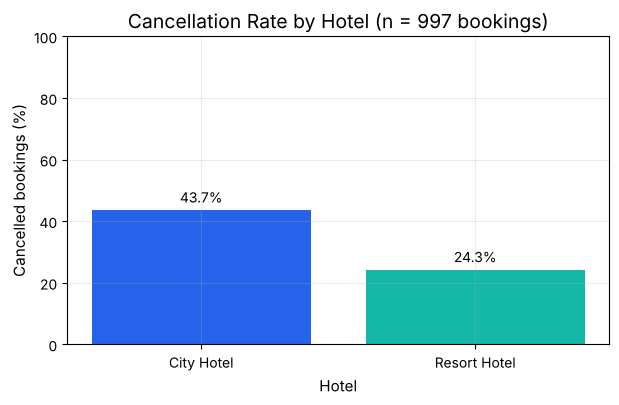

In [30]:
rate = hotel.groupby("hotel")["is_canceled"].agg(["mean", "count"])

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(rate.index, rate["mean"] * 100, color=["#2563eb", "#14b8a6"])
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.set_title(f"Cancellation Rate by Hotel (n = {rate['count'].sum()} bookings)")
ax.set_xlabel("Hotel")
ax.set_ylabel("Cancelled bookings (%)")
ax.set_ylim(0, 100)
plt.show()

**What can we observe?** City Hotel bookings were cancelled more often: 43.7 % of its 639 bookings, compared with 24.3 % of the Resort Hotel's 358. This chart does not tell us *why*; the two hotels also differ in customers, booking channels and lead times.

### Figure 2: Distribution of lead time (numerical distribution)

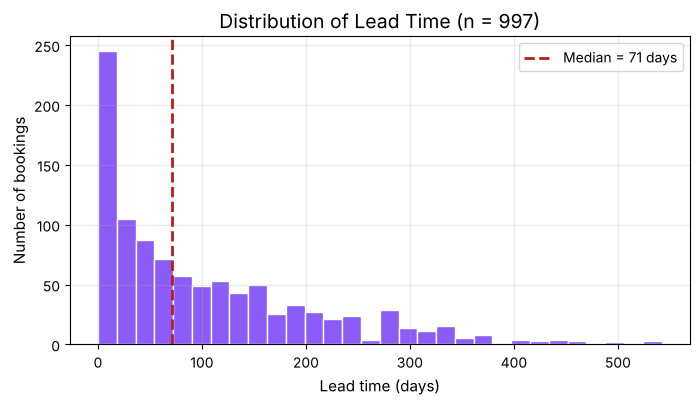

In [31]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(hotel["lead_time"], bins=30, color="#8b5cf6", edgecolor="white")
ax.axvline(hotel["lead_time"].median(), color="#b91c1c", linestyle="--",
           linewidth=2, label=f"Median = {hotel['lead_time'].median():.0f} days")
ax.set_title(f"Distribution of Lead Time (n = {hotel['lead_time'].notna().sum()})")
ax.set_xlabel("Lead time (days)")
ax.set_ylabel("Number of bookings")
ax.legend()
plt.show()

**What can we observe?** Most bookings are made less than about 100 days ahead, but there is a long right tail of bookings made up to 1.5 years in advance. Because of this skew, the median (71 days) describes a typical booking better than the mean (105 days).

### Figure 3: Lead time of kept and cancelled bookings (grouped comparison)

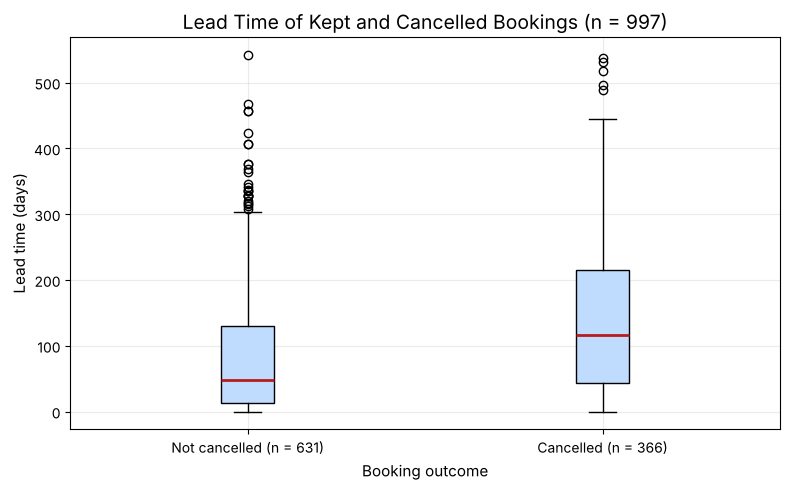

In [32]:
groups = ["Not cancelled", "Cancelled"]
lead_by_group = [hotel.loc[hotel["cancel_status"] == g, "lead_time"] for g in groups]

fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot(
    lead_by_group,
    tick_labels=[f"{g} (n = {len(d)})" for g, d in zip(groups, lead_by_group)],
    patch_artist=True,
    boxprops={"facecolor": "#bfdbfe"},
    medianprops={"color": "#b91c1c", "linewidth": 2},
)
ax.set_title(f"Lead Time of Kept and Cancelled Bookings (n = {len(hotel)})")
ax.set_xlabel("Booking outcome")
ax.set_ylabel("Lead time (days)")
fig.tight_layout()
plt.show()

**What can we observe?** Cancelled bookings were typically made much further in advance: their median lead time is 117 days compared with 48 days for kept bookings, and the whole box sits higher. Lead time is therefore **associated** with cancellation in this sample; we cannot say that booking early *causes* a cancellation.

### Figure 4: Bookings by arrival month (time-based, multi-group)

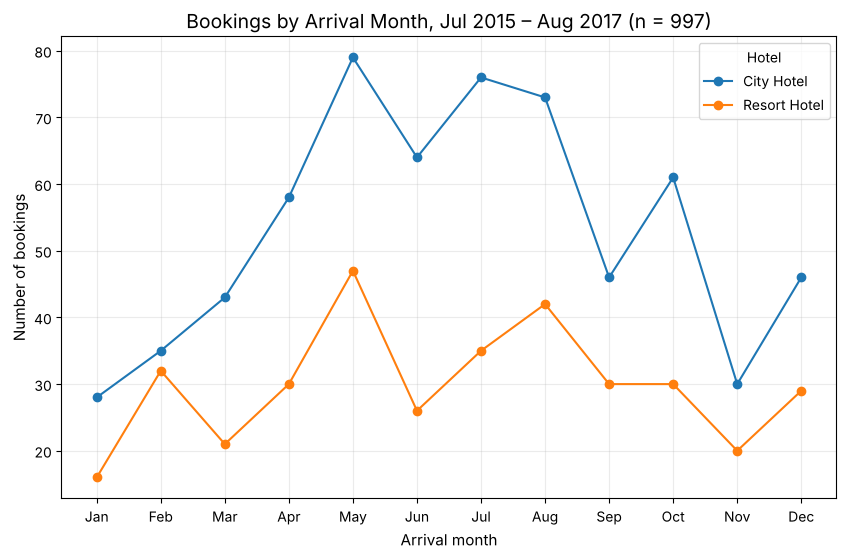

In [33]:
ax = monthly[["City Hotel", "Resort Hotel"]].plot(marker="o", figsize=(10, 6))
ax.set_xticks(range(1, 13))
ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_title(f"Bookings by Arrival Month, Jul 2015 – Aug 2017 (n = {len(hotel)})")
ax.set_xlabel("Arrival month")
ax.set_ylabel("Number of bookings")
ax.legend(title="Hotel")
plt.show()

**What can we observe?** The City Hotel has more arrivals than the Resort Hotel in every month. Across all years, May, July and August are the busiest months and January and November the quietest.

**Caution:** the data runs from July 2015 to August 2017, so only July and August appear in all three years, which inflates the summer totals. In 2016, the only complete year, May and October were the busiest months, so this chart is not proof of a summer peak.

## Conclusions, limitations, and recommendation

- answers to the three research questions;
- three to five evidence-based findings;
- at least two limitations or cautions;
- one recommendation for the hotel-management audience; and
- one useful next question that cannot be answered with the supplied variables.

**Responsible:** Whole group, led by Sandesh Bishokarma.

**Answers to the research questions**
1. **RQ1:** Do cancellation rates differ between the hotels?
Yes. City Hotel bookings were cancelled much more often (43.7 %) than Resort Hotel bookings (24.3 %).

2. **RQ2:** Is lead time associated with cancellation?
Yes, lead time is clearly associated with cancellation. Cancelled bookings had a median lead time of 117 days vs 48 days for kept bookings, and the cancellation rate rises from 14.0 % (≤ 7 days ahead) to 64.3 % (more than a year ahead).

3. **RQ3:** How does booking volume vary by arrival month for each hotel?
Over the whole sample the City Hotel is busier in every month, and January and November are the quietest months. The apparent July–August peak is mostly caused by uneven year coverage; in the complete year 2016 the busiest months were May and October.

**Key findings**
- More than a third of all bookings (36.7 %) were cancelled.
- The City Hotel has a higher cancellation rate *and* a higher median daily rate (100 € vs 77 €) than the Resort Hotel.
- Resort guests stay longer (4.2 vs 3.0 nights on average), so median booking values are almost the same at both hotels (about 270 €).
- All 116 *Non Refund* bookings in the sample were cancelled, an unexpected pattern that needs checking at the source.

**Limitations / cautions**
- The data is a 1,000-booking sample from only two hotels, 2015–2017, so results may not apply to other hotels or years.
- The years are incomplete (2015: Jul–Dec, 2017: Jan–Aug), which inflates July–August in the all-years totals.
- The patterns are associations, not causes; for example, the City Hotel's higher cancellation rate may be explained by other differences such as lead time or booking channel.
- Some decisions (keeping duplicates, keeping 0 € rates) are judgement calls; removing the duplicates would lower the overall cancellation rate only slightly.

**Recommendation for hotel management:** 
Treat bookings made far in advance, especially at the City Hotel, as a higher cancellation risk, for example by sending a reminder/confirmation message a few weeks before arrival, and plan seasonal capacity from complete years of data.

**A next question these variables can't answer:**
Why guests cancel (price found elsewhere, plans changed, group got smaller). The data has no cancellation reason or cancellation date.

## Exports and verification

Export at least `hotel_bookings_cleaned.csv` (cleaned dataset) and `hotel_booking_summary.csv` (one useful summary table).
Read the exported files back into Python and verify their shape and key columns.

**Responsible:** Anup Kandel.

In [34]:
# Save the cleaned dataset and the summary table
hotel.to_csv("../outputs/hotel_bookings_cleaned.csv", index=False)

summary = hotel.groupby("hotel").agg(
    bookings=("is_canceled", "count"),
    cancellation_rate_pct=("is_canceled", "mean"),
    median_lead_time=("lead_time", "median"),
    median_adr=("average_daily_rate", "median"),
).reset_index()
summary["cancellation_rate_pct"] = (summary["cancellation_rate_pct"] * 100).round(1)
summary.to_csv("../outputs/hotel_booking_summary.csv", index=False)
print("Files saved")

Files saved


In [35]:
# Read both files back and verify them
hotel_check = pd.read_csv("../outputs/hotel_bookings_cleaned.csv")
summary_check = pd.read_csv("../outputs/hotel_booking_summary.csv")

print("Cleaned file shape:", hotel_check.shape, "| matches:", hotel_check.shape == hotel.shape)
print("Derived columns present:",
      all(c in hotel_check.columns for c in ["arrival_date", "total_nights", "total_guests", "estimated_booking_value"]))
print("Summary file shape:", summary_check.shape)
summary_check

Cleaned file shape: (997, 29) | matches: True
Derived columns present: True
Summary file shape: (2, 5)


,hotel,bookings,cancellation_rate_pct,median_lead_time,median_adr
0,City Hotel,639,43.70,74.00,100.00
1,Resort Hotel,358,24.30,60.50,77.00
